# Subgroup prelim: safeties vs corners, edge rushers vs interior linemen
*NFL Big Data Bowl 2027 · exploratory companion (private) · rookies drafted or signed 2023 to 2025*

**Question.** Our main entry grades defensive backs and defensive linemen as two big groups. Here we split them: safeties (S) vs cornerbacks (CB), and edge rushers (EDGE: DE and OLB) vs interior linemen (IDL: DT and NT). Does the same Combine number mean the same thing on Sunday for both halves of a pair, or does lumping them together hide real differences?

**Read the Combine through body size.** Every link is a rank correlation (ρ) with draft year, weight and height held fixed. Positive ρ means the better athlete does better in games. Everything here is a **preliminary lead**, not a finding, unless it clears q < 0.05 *and* holds up on held-out draft classes. Nulls are labeled **NOT DETECTED (low power)** with the smallest effect we could have seen (MDE, 80% power).

Built from scratch on the raw competition files only (Combine results, 10 Hz Combine tracking, regular-season player plays and game tracking). No draft slot, pick or round is read. Player-level tables stay in memory; only group summaries are saved.

In [1]:
# ---- methods library (same engines as the main entry; raw competition files only) ----
"""BDB 2027 subgroup prelim: S vs CB and EDGE vs IDL.

Self-contained (raw competition files only). Same methods as the main entry (robust.py):
size-controlled rank partial correlation (draft year dummies + ranked weight + height),
beta-binomial shrinkage of rates (prior fit inside each subgroup), player bootstrap CI,
Freedman-Lane permutation p, BH-FDR inside each subgroup, leave-one-draft-class-out check,
and the minimum detectable effect (MDE, 80% power). New here: a Freedman-Lane interaction
test of whether the size-controlled link differs between the two subgroups of a pair.
Draft slot / pick / round is never read. Per-player tables stay in memory; only aggregates are written.
"""
from __future__ import annotations
import time
from pathlib import Path
import numpy as np, pandas as pd
from scipy import stats, optimize, special
from scipy.stats import norm

SEED = 2027
N_BOOT, N_PERM, N_PERM_LOSO, N_PERM_INT = 2000, 10000, 1000, 10000
MIN_N, MIN_VERDICT_N = 12, 25
MPH, ACCEL_CLIP = 2.0455, 12.0
SIZE = ["combine_weight", "combine_height"]
RANK_VAR = 1.06
ND = "NOT DETECTED (low power)"
KEY = ["game_id", "play_id", "nfl_id"]
DB_POS, DL_POS = {"CB", "SS", "FS", "DB"}, {"DE", "OLB", "DT", "NT"}
DEEP_OR_MAN = ("MAN", "DEEP_", "QUARTERS_", "PREVENT")

TESTS = [  # (col, coach label, good direction: -1 = lower/faster is better)
    ("forty", "40-yard dash", -1), ("ten_yd_split", "10-yard split", -1),
    ("c_t20_derived", "20-yard split (tracking)", -1), ("c_t10_derived", "10-yard split (tracking)", -1),
    ("c_top_mph", "Top speed (tracking)", +1), ("c_40_accel", "Peak acceleration (tracking)", +1),
    ("burst_0_100", "Burst Score 0-100 (tracking)", +1),
    ("vertical", "Vertical jump", +1), ("broad_jump", "Broad jump", +1),
    ("three_cone", "3-cone", -1), ("short_shuttle", "Short shuttle", -1),
]
TRACKING_TESTS = {"c_t20_derived", "c_t10_derived", "c_top_mph", "c_40_accel", "burst_0_100"}
DB_OUT = [  # (col, label, good direction, exposure col for the weighted check)
    ("tackle_rate", "Tackles per snap (shrunk)", +1, "n_snaps"),
    ("tfl_rate", "Tackles for loss per snap (shrunk)", +1, "n_snaps"),
    ("cov_speed_mph", "Game speed in man/deep coverage (p90, mph)", +1, "n_cov"),
    ("close_speed_mph", "Closing speed into the tackle (last 1 s, mph)", +1, "n_close"),
]
DL_OUT = [
    ("pressure_rate", "Pressure rate (shrunk)", +1, "n_rush"),
    ("sack_rate", "Sack rate (shrunk)", +1, "n_rush"),
    ("getoff_mph", "Get-off: speed 1 s after snap (mph)", +1, "n_getoff"),
    ("tfl_rate", "Tackles for loss per snap (shrunk)", +1, "n_snaps"),
    ("run_stop_rate", "Run stops (tackle at <=2 yd) per run snap (shrunk)", +1, "n_run"),
]
PAIRS = {"DB": ("S", "CB", DB_OUT), "DL": ("EDGE", "IDL", DL_OUT)}


def log(m):
    print(m, flush=True)


def _bool(s):
    return s.astype(str).str.strip().str.lower().isin({"true", "1", "1.0", "y", "yes"})


# ====================================================================== data
def find_comp() -> Path:
    for p in [Path("data"), Path("../data"), Path("../../data")]:
        if (p / "combine_tracking.csv").exists():
            return p
    hits = list(Path("/kaggle/input").rglob("combine_tracking.csv")) if Path("/kaggle/input").exists() else []
    if not hits:
        raise FileNotFoundError("Attach the NFL Big Data Bowl 2027 competition data.")
    return hits[0].parent


def roster(C: Path, pp: pd.DataFrame) -> pd.DataFrame:
    pl = pd.read_csv(C / "players.csv", usecols=["nfl_id", "draft_year", "nfl_position"])  # no draft-slot columns read
    pl = pl[pl.nfl_position.isin(DB_POS | DL_POS)].copy()
    pl["group"] = np.where(pl.nfl_position.isin(DB_POS), "DB", "DL")
    sub = {"CB": "CB", "SS": "S", "FS": "S", "DE": "EDGE", "OLB": "EDGE", "DT": "IDL", "NT": "IDL"}
    pl["sub"] = pl.nfl_position.map(sub)
    # players listed only as "DB": use where they lined up most in regular-season snaps (in this cohort they have none, so they drop out)
    lu = pp[pp.nfl_id.isin(pl.nfl_id[pl.nfl_position == "DB"])]
    if len(lu):
        m = lu.groupby("nfl_id").lined_up_position.agg(lambda v: v.value_counts().index[0])
        pl.loc[pl.nfl_position == "DB", "sub"] = pl.nfl_id.map(m).map(
            {"CB": "CB", "SLOT_CB": "CB", "HIGH_SAFETY": "S", "BOX_SAFETY": "S"})
    pl = pl.dropna(subset=["sub"])
    cr = pd.read_csv(C / "combine_results.csv", usecols=["nfl_id"] + SIZE + [
        "ten_yd_split", "forty", "vertical", "broad_jump", "three_cone", "short_shuttle"]).drop_duplicates("nfl_id")
    return pl.merge(cr, on="nfl_id", how="left")


def _attempt(g: pd.DataFrame) -> dict:
    s, x = g.s.to_numpy(float), g.x.to_numpy(float)
    t = g.t.to_numpy(float)
    out = dict(max_s=np.nan, accel=np.nan, t10=np.nan, t20=np.nan)
    if len(g) < 8 or not np.isfinite(s).any():
        return out
    out["max_s"] = float(np.nanmax(s))
    ds = np.diff(s) * 10.0
    ds = ds[np.abs(ds) <= ACCEL_CLIP]
    if ds.size:
        out["accel"] = float(ds.max())
    start = float(np.nanmax(x) - 40.0); nf = min(8, len(g))

    def cross(target):
        if x[0] >= target:
            c = np.polyfit(t[:nf], x[:nf], 1)
            return np.nan if abs(c[0]) < 1e-6 else float((target - c[1]) / c[0])
        hit = np.where(x >= target)[0]
        if not len(hit):
            return np.nan
        i = int(hit[0])
        if i == 0 or x[i] == x[i - 1]:
            return float(t[i])
        return float(t[i - 1] + (target - x[i - 1]) / (x[i] - x[i - 1]) * (t[i] - t[i - 1]))
    t0 = cross(start)
    if np.isfinite(t0):
        for yd, k in ((10, "t10"), (20, "t20")):
            tc = cross(start + yd)
            out[k] = tc - t0 if np.isfinite(tc) else np.nan
    return out


def combine_tracking(C: Path, ids) -> pd.DataFrame:
    """40-yard dash from the 10 Hz Combine sensor: best attempt (highest top speed)."""
    ct = pd.read_csv(C / "combine_tracking.csv", usecols=["event_id", "nfl_id", "entity_type", "time", "drill_type", "x", "s"])
    ct = ct[(ct.entity_type == "PLAYER") & (ct.drill_type == "FORTY_YARD_DASH") & ct.nfl_id.isin(ids)].copy()
    ct["time"] = pd.to_datetime(ct.time)
    ct = ct.sort_values(["event_id", "time"])
    ct["t"] = (ct.time - ct.groupby("event_id").time.transform("min")).dt.total_seconds()
    rows = [dict(nfl_id=n, **_attempt(g)) for (e, n), g in ct.groupby(["event_id", "nfl_id"], sort=False)]
    a = pd.DataFrame(rows).dropna(subset=["max_s"])
    best = a.loc[a.groupby("nfl_id").max_s.idxmax()].copy()
    best["c_top_mph"] = best.max_s * MPH
    return best.rename(columns={"t10": "c_t10_derived", "t20": "c_t20_derived", "accel": "c_40_accel"})[
        ["nfl_id", "c_top_mph", "c_t10_derived", "c_t20_derived", "c_40_accel"]]


def plays(C: Path, ids) -> pd.DataFrame:
    cols = KEY + ["team_abbr", "possession_team", "lined_up_position", "pass_result", "play_nullified_by_penalty",
                  "yards_gained", "coverage_assignment", "sack", "tackle", "assist", "tackle_for_loss", "time_to_pressure"]
    parts = [ch[ch.nfl_id.isin(ids)] for ch in pd.read_csv(C / "player_play.csv", usecols=cols, chunksize=100_000)]
    pp = pd.concat(parts, ignore_index=True)
    g = pd.read_csv(C / "games.csv", usecols=["game_id", "season_type"])
    pp = pp[pp.game_id.isin(g.game_id[g.season_type == "REG"])]
    pp = pp[(pp.play_nullified_by_penalty == "N") & (pp.team_abbr != pp.possession_team)].copy()
    t = pd.to_numeric(pp.tackle, errors="coerce"); a = pd.to_numeric(pp.assist, errors="coerce")
    pp["inv"] = (t >= 1) | (a == 1)
    pp["tfl"] = _bool(pp.tackle_for_loss)
    pp["is_pass"] = pp.pass_result.notna()
    pp["sack_n"] = pd.to_numeric(pp.sack, errors="coerce").fillna(0).clip(0, 1)
    pp["press"] = pp.time_to_pressure.notna()
    pp["stop"] = pp.inv & (pd.to_numeric(pp.yards_gained, errors="coerce") <= 2)
    pp["rush"] = pp.is_pass & pp.lined_up_position.isin(["EDGE", "INTERIOR_LINE"])
    ca = pp.coverage_assignment.fillna("")
    pp["cov"] = pp.is_pass & ca.str.startswith(DEEP_OR_MAN)
    return pp


def game_tracking(C: Path, pp: pd.DataFrame, chunksize=2_000_000) -> dict:
    """One streaming pass over the three game-tracking files.
    DB coverage plays -> per-play top speed. DL rush plays + DB tackle plays -> keep (time, s, event) frames."""
    cov = pp.loc[pp["cov"] & (pp.grp == "DB"), KEY]
    rush = pp.loc[pp.rush & (pp.grp == "DL"), KEY]
    tak = pp.loc[pp.inv & (pp.grp == "DB"), KEY]
    ids = set(pp.nfl_id)
    k_cov = pd.MultiIndex.from_frame(cov); k_rush = pd.MultiIndex.from_frame(rush); k_tak = pd.MultiIndex.from_frame(tak)
    cov_parts, fr_parts = [], []
    files = sorted(C.glob("game_tracking_*.csv"))
    for f in files:
        t0 = time.time()
        for ch in pd.read_csv(f, usecols=KEY + ["time", "s", "event"], dtype={"s": "float32"}, chunksize=chunksize):
            ch = ch[ch.nfl_id.isin(ids)]
            if not len(ch):
                continue
            mi = pd.MultiIndex.from_frame(ch[KEY])
            c = ch[mi.isin(k_cov)]
            if len(c):
                cov_parts.append(c.groupby(KEY, sort=False).s.max().reset_index())
            keep = mi.isin(k_rush) | mi.isin(k_tak)
            if keep.any():
                fr_parts.append(ch[keep])
        log(f"  {f.name}: {time.time() - t0:.0f}s")
    cv = pd.concat(cov_parts).groupby(KEY, as_index=False).s.max()
    fr = pd.concat(fr_parts, ignore_index=True)
    fr["time"] = pd.to_datetime(fr.time)
    fr = fr.sort_values(KEY + ["time"])
    # DL get-off: speed nearest to 1.0 s after the snap (within 0.15 s)
    rf = fr.merge(rush, on=KEY)
    snap = rf[rf.event.isin(["ball_snap", "autoevent_ballsnap"])].groupby(KEY).time.min().rename("t_snap")
    rf = rf.join(snap, on=KEY, how="inner")
    rf["d"] = ((rf.time - rf.t_snap).dt.total_seconds() - 1.0).abs()
    rf = rf[rf.d <= 0.15]
    getoff = rf.loc[rf.groupby(KEY).d.idxmin(), KEY + ["s"]].rename(columns={"s": "s1"})
    # DB closing: mean speed over the 1.0 s before the 'tackle' event, on plays he made or assisted the tackle
    tf = fr.merge(tak, on=KEY)
    tk = tf[tf.event == "tackle"].groupby(KEY).time.min().rename("t_tk")
    tf = tf.join(tk, on=KEY, how="inner")
    dt = (tf.t_tk - tf.time).dt.total_seconds()
    close = tf[(dt >= 0) & (dt <= 1.0)].groupby(KEY, as_index=False).s.mean().rename(columns={"s": "s_close"})
    return dict(cov=cv, getoff=getoff, close=close)


def fit_beta_binomial(k, n):
    k, n = np.asarray(k, float), np.asarray(n, float)

    def nll(th):
        a, b = np.exp(th)
        return -np.sum(special.betaln(k + a, n - k + b) - special.betaln(a, b))
    mu = (k.sum() / n.sum()).clip(1e-4, 1 - 1e-4); best = None
    for s in (3, 30, 300, 3000):
        r = optimize.minimize(nll, np.log([mu * s, (1 - mu) * s]), method="Nelder-Mead",
                              options=dict(xatol=1e-4, fatol=1e-6, maxiter=2000))
        best = r if best is None or r.fun < best.fun else best
    return tuple(np.exp(best.x))


def shrink(d: pd.DataFrame, k: str, n: str, min_n: int) -> pd.Series:
    """Empirical-Bayes posterior-mean rate, prior fit inside each subgroup."""
    out = pd.Series(np.nan, index=d.index)
    for _, g in d.groupby("sub"):
        g = g[(g[n] >= min_n)]
        if len(g) < 8:
            continue
        a, b = fit_beta_binomial(g[k], g[n])
        out[g.index] = (a + g[k]) / (a + b + g[n])
    return out


def burst_score(d: pd.DataFrame) -> pd.Series:
    """0-100 within-subgroup blend of tracked 20-yard time (faster = better) and the two jumps."""
    z = pd.DataFrame(index=d.index)
    for c, sg in (("c_t20_derived", -1), ("vertical", 1), ("broad_jump", 1)):
        z[c] = sg * (d[c] - d.groupby("sub")[c].transform("mean")) / d.groupby("sub")[c].transform("std")
    m = z.mean(axis=1).where(z.notna().sum(axis=1) >= 2)
    return (m.groupby(d["sub"]).rank(pct=True) * 100).round(1)


def build(C: Path | None = None) -> pd.DataFrame:
    C = C or find_comp(); t0 = time.time()
    pl0 = pd.read_csv(C / "players.csv", usecols=["nfl_id", "nfl_position"])
    ids0 = set(pl0.nfl_id[pl0.nfl_position.isin(DB_POS | DL_POS)])
    pp = plays(C, ids0)
    P = roster(C, pp)
    pp = pp.merge(P[["nfl_id", "group", "sub"]].rename(columns={"group": "grp"}), on="nfl_id")
    log(f"plays loaded ({len(pp):,} defensive REG snaps) {time.time() - t0:.0f}s")
    P = P.merge(combine_tracking(C, set(P.nfl_id)), on="nfl_id", how="left")
    log(f"combine tracking done {time.time() - t0:.0f}s")
    G = game_tracking(C, pp)
    log(f"game tracking done {time.time() - t0:.0f}s")
    a = pp.groupby("nfl_id").agg(n_snaps=("inv", "size"), n_inv=("inv", "sum"), n_tfl=("tfl", "sum"))
    r = pp[pp.rush].groupby("nfl_id").agg(n_rush=("rush", "size"), n_press=("press", "sum"), n_sack=("sack_n", "sum"))
    ru = pp[~pp.is_pass].groupby("nfl_id").agg(n_run=("stop", "size"), n_stop=("stop", "sum"))
    cv = G["cov"].groupby("nfl_id").s.agg(n_cov="size", cov_p90=lambda v: v.quantile(0.90))
    go = G["getoff"].groupby("nfl_id").s1.agg(n_getoff="size", s1="median")
    cl = G["close"].groupby("nfl_id").s_close.agg(n_close="size", sc="median")
    P = P.set_index("nfl_id").join([a, r, ru, cv, go, cl]).reset_index()
    for c in ["n_snaps", "n_inv", "n_tfl", "n_rush", "n_press", "n_sack", "n_run", "n_stop", "n_cov", "n_getoff", "n_close"]:
        P[c] = P[c].fillna(0)
    P["tackle_rate"] = shrink(P, "n_inv", "n_snaps", 100)
    P["tfl_rate"] = shrink(P, "n_tfl", "n_snaps", 100)
    P["pressure_rate"] = shrink(P, "n_press", "n_rush", 20)
    P["sack_rate"] = shrink(P, "n_sack", "n_rush", 20)
    P["run_stop_rate"] = shrink(P, "n_stop", "n_run", 50)
    P["cov_speed_mph"] = np.where(P.n_cov >= 20, P.cov_p90 * MPH, np.nan)
    P["getoff_mph"] = np.where(P.n_getoff >= 20, P.s1 * MPH, np.nan)
    P["close_speed_mph"] = np.where(P.n_close >= 10, P.sc * MPH, np.nan)
    P["burst_0_100"] = burst_score(P)
    bad = [c for c in P.columns if any(k in c.lower() for k in ("round", "pick", "overall", "slot"))]
    assert not bad, f"draft-slot columns present: {bad}"
    log(f"player table built: {len(P)} DB/DL players, {time.time() - t0:.0f}s")
    return P


# ====================================================================== stats (same engines as robust.py)
def _rank(v):
    return stats.rankdata(v, axis=-1)


def _design(df, ctrl):
    cols = [np.ones(len(df))]
    if df["draft_year"].nunique() > 1:
        cols += list(pd.get_dummies(df["draft_year"].astype(str), drop_first=True).to_numpy(float).T)
    cols += [_rank(df[c].to_numpy(float)) for c in ctrl]
    return np.column_stack(cols)


def _resid(v, Z):
    return v - Z @ np.linalg.lstsq(Z, v, rcond=None)[0]


def _corr(a, b):
    a = a - a.mean(); b = b - b.mean(); d = np.sqrt((a * a).sum() * (b * b).sum())
    return float((a * b).sum() / d) if d > 0 else np.nan


def _year_only(s, x, y):
    Z = _design(s, [])
    return _corr(_resid(_rank(x), Z), _resid(_rank(y), Z))


def boot_partial(s, x, y, ctrl, B=N_BOOT, seed=SEED):
    n = len(x); idx = np.random.default_rng(seed).integers(0, n, size=(B, n))
    yr = pd.get_dummies(s["draft_year"].astype(str), drop_first=True).to_numpy(float)
    cols = [np.ones((B, n))] + [yr[:, j][idx] for j in range(yr.shape[1])] + [_rank(s[c].to_numpy(float)[idx]) for c in ctrl]
    Z = np.stack(cols, axis=2); H = Z @ np.linalg.pinv(Z)
    rx, ry = _rank(x[idx]), _rank(y[idx])
    ex = rx - np.einsum("bij,bj->bi", H, rx); ey = ry - np.einsum("bij,bj->bi", H, ry)
    with np.errstate(invalid="ignore", divide="ignore"):
        r = (ex * ey).sum(1) / np.sqrt((ex ** 2).sum(1) * (ey ** 2).sum(1))
    r = r[np.isfinite(r)]
    return tuple(np.percentile(r, [2.5, 97.5])) if len(r) > 100 else (np.nan, np.nan)


def perm_fl(ex, ey, Z, P=N_PERM, seed=SEED):
    """Freedman-Lane: permute reduced-model residuals of y, re-residualise, correlate with x residual."""
    n = len(ex); r_obs = _corr(ex, ey)
    idx = np.argsort(np.random.default_rng(seed).random((P, n)), axis=1)
    e = ey[idx]; H = Z @ np.linalg.pinv(Z); me = e - e @ H
    with np.errstate(invalid="ignore", divide="ignore"):
        r = (me @ ex) / (np.sqrt((ex ** 2).sum()) * np.sqrt((me ** 2).sum(1)))
    return float((1 + np.sum(np.abs(r) >= abs(r_obs) - 1e-12)) / (P + 1))


def _nscore(v, cls):
    out = np.zeros(len(v))
    for c in np.unique(cls):
        m = cls == c; r = stats.rankdata(v[m]); out[m] = norm.ppf((r - 0.5) / m.sum())
    return out


def _ridge(Xtr, ytr, Xte, alpha=5.0):
    mu, sd = Xtr.mean(0), Xtr.std(0); sd[sd == 0] = 1
    A = (Xtr - mu) / sd; ym = ytr.mean()
    b = np.linalg.solve(A.T @ A + alpha * np.eye(A.shape[1]), A.T @ (ytr - ym))
    return ym + ((Xte - mu) / sd) @ b


def _r2(y, p):
    return 1 - np.sum((y - p) ** 2) / np.sum(y ** 2)


def loso(s, x, y, ctrl, P=N_PERM_LOSO, seed=SEED):
    """Held-out draft classes: train size-only vs size+test on two classes, predict the third."""
    cls = s["draft_year"].to_numpy(); res = dict(ho_dr2=np.nan, ho_pos=0, ho_folds=0, ho_p=np.nan)
    folds = [c for c in np.unique(cls) if (cls == c).sum() >= 5 and (cls != c).sum() >= 12]
    if len(folds) < 2:
        return res
    base = np.column_stack([_nscore(s[c].to_numpy(float), cls) for c in ctrl])
    zx, zy = _nscore(x, cls), _nscore(y, cls)

    def run(zxx):
        Xf = np.column_stack([base, zxx]); out = []
        for f in folds:
            te = cls == f; tr = ~te
            out.append((zy[te], _ridge(base[tr], zy[tr], base[te]), _ridge(Xf[tr], zy[tr], Xf[te])))
        yt = np.concatenate([o[0] for o in out]); ps = np.concatenate([o[1] for o in out]); pf = np.concatenate([o[2] for o in out])
        return _r2(yt, pf) - _r2(yt, ps), sum(_r2(o[0], o[2]) - _r2(o[0], o[1]) > 0 for o in out)
    d, pos = run(zx)
    rng = np.random.default_rng(seed); null = np.empty(P)
    groups = [np.where(cls == c)[0] for c in np.unique(cls)]
    for b in range(P):
        zp = zx.copy()
        for ii in groups:
            zp[ii] = zx[rng.permutation(ii)]
        null[b] = run(zp)[0]
    res.update(ho_dr2=d, ho_pos=int(pos), ho_folds=len(folds), ho_p=float((1 + (null >= d).sum()) / (P + 1)))
    return res


def _se(n, k):
    df = np.asarray(n, float) - np.asarray(k, float) - 3
    return np.where(df > 1, np.sqrt(RANK_VAR / np.where(df > 1, df, np.nan)), np.nan)


def mde(n, k, alpha=0.05, power=0.80):
    return np.tanh((norm.ppf(1 - alpha / 2) + norm.ppf(power)) * _se(n, k))


def mde_diff(n1, n2, k, alpha=0.05, power=0.80):
    """Smallest difference in size-controlled rho between two independent subgroups (around rho = 0)."""
    se = np.sqrt(_se(n1, k) ** 2 + _se(n2, k) ** 2)
    return np.tanh((norm.ppf(1 - alpha / 2) + norm.ppf(power)) * se)


def bh(p: pd.Series) -> pd.Series:
    q = pd.Series(np.nan, index=p.index); m = p.notna()
    if m.sum():
        pv = p[m].to_numpy(); o = np.argsort(pv); n = len(pv)
        adj = np.minimum.accumulate((pv[o] * n / np.arange(1, n + 1))[::-1])[::-1]
        r = np.empty(n); r[o] = np.minimum(adj, 1); q[m] = r
    return q


def cell(sub: pd.DataFrame, test, outcome, sign, ctrl_role=None) -> dict:
    need = [test, outcome, "draft_year"] + SIZE + ([ctrl_role] if ctrl_role else [])
    s = sub[need].dropna().reset_index(drop=True)
    out = dict(n=len(s))
    if len(s) < MIN_N or s[test].nunique() < 3 or s[outcome].nunique() < 3:
        return out
    x, y = s[test].to_numpy(float) * sign, s[outcome].to_numpy(float)  # sign: + = better athlete does better
    Z = _design(s, SIZE)
    if ctrl_role:
        Z = np.column_stack([Z, (s[ctrl_role] == s[ctrl_role].iloc[0]).to_numpy(float)])
    ex, ey = _resid(_rank(x), Z), _resid(_rank(y), Z)
    out.update(rho_year=_year_only(s, x, y), rho=_corr(ex, ey), k=Z.shape[1] - 1)
    if ctrl_role:  # pooled reference: point estimate + permutation p only
        out["p"] = perm_fl(ex, ey, Z, P=2000)
        return out
    out["lo"], out["hi"] = boot_partial(s, x, y, SIZE)
    out["p"] = perm_fl(ex, ey, Z)
    out.update(loso(s, x, y, SIZE))
    return out


def run_cells(P: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for grp, (a, b, outs) in PAIRS.items():
        for sub in (a, b):
            d = P[P["sub"] == sub]; t0 = time.time()
            for oc, ol, og, _ in outs:
                for tc, tl, tg in TESTS:
                    rows.append(dict(group=grp, sub=sub, test=tc, test_label=tl, outcome=oc, outcome_label=ol,
                                     tracking=tc in TRACKING_TESTS, **cell(d, tc, oc, tg * og)))
            log(f"  {sub}: {time.time() - t0:.0f}s")
        d = P[P.group == grp]
        for oc, ol, og, _ in outs:
            for tc, tl, tg in TESTS:
                rows.append(dict(group=grp, sub=f"{grp} pooled", test=tc, test_label=tl, outcome=oc, outcome_label=ol,
                                 tracking=tc in TRACKING_TESTS, **cell(d, tc, oc, tg * og, ctrl_role="sub")))
    t = pd.DataFrame(rows)
    t["q"] = np.nan
    for sub, g in t.groupby("sub"):
        t.loc[g.index, "q"] = bh(g.p)
    t["mde80"] = mde(t.n, t.k.fillna(4))
    t["held_out_ok"] = (t.ho_dr2 > 0) & (t.ho_p < 0.10) & (t.ho_pos >= 2)
    t["verdict"] = t.apply(verdict, axis=1)
    return t


def verdict(r) -> str:
    if "pooled" in r["sub"]:
        return "reference"
    if not np.isfinite(r.get("rho", np.nan)):
        return "TOO FEW TO TELL"
    if r.n < MIN_VERDICT_N:
        return "TOO FEW TO TELL"
    ci = (r.lo > 0) or (r.hi < 0)
    if r.q < 0.05 and ci and r.held_out_ok:
        return "TRANSLATES"
    if ci or r.p < 0.05:
        return "LEAD (preliminary)"
    if abs(r.rho_year) >= 0.30 and abs(r.rho) <= abs(r.rho_year) / 2:
        return "SIZE, NOT SPEED"
    return ND


# ====================================================================== interaction (does the slope differ?)
def _zmats(s):
    yr = s["draft_year"].to_numpy()
    D = np.column_stack([(yr == v).astype(float) for v in np.unique(yr)[1:]]) if len(np.unique(yr)) > 1 else np.zeros((len(s), 0))
    return D, s[SIZE].to_numpy(float)


def _within(D, S, x, y):
    Z = np.column_stack([np.ones(len(x)), D] + [_rank(S[:, j]) for j in range(S.shape[1])])
    ex, ey = _resid(_rank(x), Z), _resid(_rank(y), Z)
    return ex / ex.std(), ey / ey.std()


def interaction(P, grp, a, b, test, outcome, sign, B=N_BOOT, NP=N_PERM_INT, seed=SEED):
    """Size-controlled residuals are built inside each subgroup (so level and size differences between
    the subgroups cannot leak in). Then on the stacked residuals: e_y ~ e_x + e_x*[subgroup b] + [subgroup b];
    Freedman-Lane permutation of the reduced-model (no interaction) residuals gives the p-value.
    Effect size = rho_a - rho_b, with a stratified player bootstrap CI."""
    need = [test, outcome, "draft_year"] + SIZE
    sa = P[P["sub"] == a][need].dropna().reset_index(drop=True)
    sb = P[P["sub"] == b][need].dropna().reset_index(drop=True)
    out = dict(group=grp, test=test, outcome=outcome, n_a=len(sa), n_b=len(sb))
    if min(len(sa), len(sb)) < MIN_N:
        return out
    xa, ya = sa[test].to_numpy(float) * sign, sa[outcome].to_numpy(float)
    xb, yb = sb[test].to_numpy(float) * sign, sb[outcome].to_numpy(float)
    Da, Sa = _zmats(sa); Db, Sb = _zmats(sb)
    exa, eya = _within(Da, Sa, xa, ya); exb, eyb = _within(Db, Sb, xb, yb)
    ra, rb = _corr(exa, eya), _corr(exb, eyb)
    ex = np.r_[exa, exb]; ey = np.r_[eya, eyb]; g = np.r_[np.zeros(len(exa)), np.ones(len(exb))]
    Zr = np.column_stack([np.ones(len(ex)), g, ex])
    inter = ex * g
    e_int = _resid(inter, Zr); e_y = _resid(ey, Zr)
    beta_obs = (e_int @ e_y) / (e_int @ e_int)
    rng = np.random.default_rng(seed); fit = ey - e_y
    idx = np.argsort(rng.random((NP, len(ey))), axis=1)
    ystar = fit[None, :] + e_y[idx]
    H = Zr @ np.linalg.pinv(Zr); res = ystar - ystar @ H.T
    bnull = (res @ e_int) / (e_int @ e_int)
    p = float((1 + np.sum(np.abs(bnull) >= abs(beta_obs) - 1e-12)) / (NP + 1))
    # stratified bootstrap CI of rho_a - rho_b (re-residualise inside each resample)
    r1 = np.random.default_rng(seed + 1); diffs = []
    for _ in range(B):
        ia = r1.integers(0, len(sa), len(sa)); ib = r1.integers(0, len(sb), len(sb))
        try:
            da = _corr(*_within(Da[ia], Sa[ia], xa[ia], ya[ia])); db = _corr(*_within(Db[ib], Sb[ib], xb[ib], yb[ib]))
        except Exception:
            continue
        if np.isfinite(da) and np.isfinite(db):
            diffs.append(da - db)
    lo, hi = np.percentile(diffs, [2.5, 97.5]) if len(diffs) > 100 else (np.nan, np.nan)
    k = 2 + len(SIZE)
    out.update(rho_a=ra, rho_b=rb, diff=ra - rb, diff_lo=lo, diff_hi=hi, p_int=p,
               mde_diff=float(mde_diff(len(sa), len(sb), k)))
    return out


def run_interactions(P: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for grp, (a, b, outs) in PAIRS.items():
        t0 = time.time()
        for oc, ol, og, _ in outs:
            for tc, tl, tg in TESTS:
                rows.append(dict(sub_a=a, sub_b=b, test_label=tl, outcome_label=ol, tracking=tc in TRACKING_TESTS,
                                 **interaction(P, grp, a, b, tc, oc, tg * og)))
        log(f"  {a} vs {b}: {time.time() - t0:.0f}s")
    t = pd.DataFrame(rows)
    t["q_int"] = np.nan
    for grp, g in t.groupby("group"):
        t.loc[g.index, "q_int"] = bh(g.p_int)
    small = t[["n_a", "n_b"]].min(axis=1) < MIN_VERDICT_N

    def v(r):
        if not np.isfinite(r.get("diff", np.nan)) or min(r.n_a, r.n_b) < MIN_N:
            return "TOO FEW TO TELL"
        if r.q_int < 0.05:
            return "REAL DIFFERENCE"
        if r.p_int < 0.05:
            return "LEAD (preliminary)"
        return ND
    t["verdict"] = t.apply(v, axis=1)
    t.loc[small & t["diff"].notna(), "verdict"] = "TOO FEW TO TELL"
    return t


def sample_sizes(P: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for grp, (a, b, outs) in PAIRS.items():
        for sub in (a, b):
            d = P[P["sub"] == sub]
            r = dict(group=grp, subgroup=sub, players=len(d), with_size=int(d[SIZE].notna().all(axis=1).sum()),
                     with_40_tracking=int(d.c_top_mph.notna().sum()), with_official_40=int(d.forty.notna().sum()))
            for oc, *_ in outs:
                r[f"n_{oc}"] = int(d[[oc] + SIZE].notna().all(axis=1).sum())
            nn = int(d[["c_top_mph", outs[0][0]] + SIZE].notna().all(axis=1).sum())
            r["n_core"] = nn; r["mde80_core"] = float(mde(nn, 4))
            rows.append(r)
    return pd.DataFrame(rows)


In [2]:
# ---- figure helpers ----
import textwrap
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
COL = {"S": "#0072B2", "CB": "#E69F00", "EDGE": "#D55E00", "IDL": "#009E73", "pooled": "#444444"}
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .25, "figure.dpi": 110, "savefig.dpi": 150})
TL = {c: l for c, l, _ in TESTS}


def fig_power(ns, path):
    fig, ax = plt.subplots(figsize=(8.5, 3.4))
    order = ["S", "CB", "EDGE", "IDL"]; d = ns.set_index("subgroup").loc[order]
    b = ax.bar(order, d.n_core, color=[COL[o] for o in order])
    for r, (o, row) in zip(b, d.iterrows()):
        ax.text(r.get_x() + r.get_width() / 2, r.get_height() + .8, f"n {int(row.n_core)}\nneeds |ρ| ≥ {row.mde80_core:.2f}",
                ha="center", va="bottom", fontsize=8.5)
    ax.axhline(25, color="#999", ls="--", lw=1); ax.text(-0.45, 25.6, "25 = smallest group we grade", fontsize=7.5, ha="left", color="#666")
    ax.set_ylim(0, max(d.n_core) * 1.45); ax.set_ylabel("players with size, tracked 40\nand a main game result")
    ax.set_title("Who is in each subgroup, and the smallest link each can detect (80% power)")
    fig.tight_layout(); fig.savefig(path); plt.show()


def fig_forest(cells, ints, grp, path):
    a, b, outs = PAIRS[grp]
    c = cells[cells.group == grp]; it = ints[ints.group == grp].set_index(["test", "outcome"])
    fig, axes = plt.subplots(1, len(outs), figsize=(2.55 * len(outs) + 1.6, 6.4), sharey=True)
    ys = np.arange(len(TESTS))[::-1]
    for ax, (oc, ol, *_ ) in zip(axes, outs):
        for j, (tc, tl, _) in enumerate(TESTS):
            y0 = ys[j]
            for sub, off in ((a, .18), (b, -.18)):
                r = c[(c["sub"] == sub) & (c.test == tc) & (c.outcome == oc)]
                if not len(r) or not np.isfinite(r.rho.iloc[0]):
                    continue
                r = r.iloc[0]; small = r.n < 25
                ax.plot([r.lo, r.hi], [y0 + off] * 2, color=COL[sub], lw=1.4, alpha=.35 if small else .9)
                ax.plot(r.rho, y0 + off, "o", ms=5, mfc="white" if small else COL[sub], mec=COL[sub])
            p = c[(c["sub"] == f"{grp} pooled") & (c.test == tc) & (c.outcome == oc)]
            if len(p) and np.isfinite(p.rho.iloc[0]):
                ax.plot(p.rho.iloc[0], y0, "D", ms=4, mfc="none", mec=COL["pooled"])
            if (tc, oc) in it.index and it.loc[(tc, oc), "p_int"] < 0.05 and it.loc[(tc, oc), "verdict"] != "TOO FEW TO TELL":
                ax.text(1.02, y0, "Δ", color="#CC0000", fontsize=9, fontweight="bold", va="center", transform=ax.get_yaxis_transform())
        ax.axvline(0, color="#333", lw=.8); ax.set_xlim(-1, 1); ax.set_title("\n".join(textwrap.wrap(ol, 26)), fontsize=8.5)
        ax.set_xlabel("ρ, size held fixed")
    axes[0].set_yticks(ys); axes[0].set_yticklabels([tl for _, tl, _ in TESTS])
    h = [Line2D([], [], marker="o", color=COL[a], label=a), Line2D([], [], marker="o", color=COL[b], label=b),
         Line2D([], [], marker="D", ls="", mfc="none", mec=COL["pooled"], label=f"{grp} pooled (role held fixed)"),
         Line2D([], [], marker="o", ls="", mfc="white", mec="#888", label="hollow = under 25 players"),
         Line2D([], [], marker="$Δ$", ls="", color="#CC0000", label="slopes differ, p < 0.05 (lead only)")]
    fig.legend(handles=h, loc="lower center", ncol=5, fontsize=8, frameon=False)
    name = {"DB": "Safeties vs corners", "DL": "Edge rushers vs interior linemen"}[grp]
    fig.suptitle(f"{name}: does the same Combine number mean the same thing on Sunday?\n"
                 "Right of zero = the better athlete does better. Bars = 95% bootstrap interval.", fontsize=10)
    fig.tight_layout(rect=(0, .05, .97, 1)); fig.savefig(path); plt.show()


def fig_diff(ints, path, top=12):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
    for ax, grp in zip(axes, ["DB", "DL"]):
        a, b, _ = PAIRS[grp]
        d = ints[(ints.group == grp) & ints["diff"].notna() & (ints[["n_a", "n_b"]].min(axis=1) >= 25)].sort_values("p_int").head(top)[::-1]
        y = np.arange(len(d))
        m = d.mde_diff.median()
        ax.axvspan(-m, m, color="#eeeeee", zorder=0)
        col = np.where(d.verdict == "REAL DIFFERENCE", "#009E73", np.where(d.verdict.str.startswith("LEAD"), "#E69F00", "#7f7f7f"))
        ax.hlines(y, d.diff_lo, d.diff_hi, color=col, lw=1.6); ax.scatter(d["diff"], y, c=col, zorder=3, s=22)
        ax.set_yticks(y); ax.set_yticklabels([f"{TL[t]} → {o.split(' (')[0]}" for t, o in zip(d.test, d.outcome_label)], fontsize=7.5)
        ax.axvline(0, color="#333", lw=.8); ax.set_xlabel(f"ρ({a}) − ρ({b}), size held fixed")
        ax.set_title(f"{a} vs {b}: {top} biggest gaps\n(grey = too small to detect, MDE ≈ {m:.2f})", fontsize=9.5)
    fig.legend(handles=[Patch(color="#E69F00", label="LEAD (p < 0.05, q ≥ 0.05)"), Patch(color="#7f7f7f", label="NOT DETECTED (low power)")],
               loc="lower center", ncol=2, frameon=False, fontsize=8)
    fig.suptitle("Do the subgroups really differ? Interaction tests (Freedman–Lane, 10,000 permutations)", fontsize=10)
    fig.tight_layout(rect=(0, .05, 1, .96)); fig.savefig(path); plt.show()


In [3]:
from pathlib import Path
from IPython.display import display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
OUTDIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("out_sub")
FIGDIR = OUTDIR / "figs"; FIGDIR.mkdir(parents=True, exist_ok=True)
P = build()          # per-player table: kept in memory only, never written to disk

plays loaded (113,955 defensive REG snaps) 1s


combine tracking done 2s


  game_tracking_2023.csv: 4s


  game_tracking_2024.csv: 7s


  game_tracking_2025.csv: 10s


game tracking done 25s


player table built: 231 DB/DL players, 26s


## 1. Who is in each subgroup
Players listed as CB → CB; SS and FS → S; DE and OLB → EDGE; DT and NT → IDL. The five players listed only as "DB" have no regular-season snaps in the data, so they drop out. Each game result has its own minimum: 100 defensive snaps for per-snap rates, 20 pass-rush snaps for pressure and sack rate, 20 man/deep coverage snaps for coverage speed, 10 tracked tackles for closing speed, 50 run snaps for run stops. Rates are shrunk toward the subgroup average (beta-binomial) so a hot 120-snap sample does not dominate.

,group,subgroup,players,with_size,with_40_tracking,with_official_40,n_tackle_rate,n_tfl_rate,n_cov_speed_mph,n_close_speed_mph,n_core,mde80_core,n_pressure_rate,n_sack_rate,n_getoff_mph,n_run_stop_rate
0,DB,S,53,53,45,46,31.0,31,36.0,31.0,26,0.58,NaN,NaN,NaN,NaN
1,DB,CB,60,60,51,52,38.0,38,43.0,38.0,32,0.52,NaN,NaN,NaN,NaN
2,DL,EDGE,66,66,52,53,NaN,45,NaN,NaN,38,0.48,50.0,50.0,50.0,43.0
3,DL,IDL,52,52,41,41,NaN,31,NaN,NaN,33,0.51,39.0,39.0,39.0,35.0


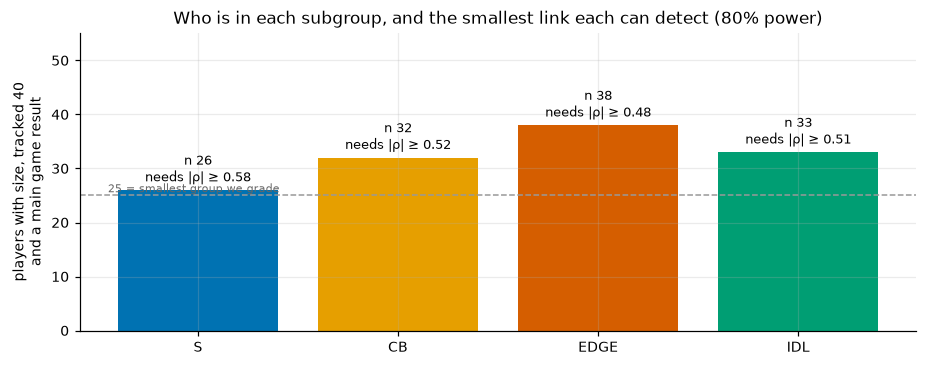

In [4]:
ns = sample_sizes(P)
display(ns.round(2))
fig_power(ns, FIGDIR / "sub_fig1_sample_power.png")

In [5]:
t0 = time.time()
cells = run_cells(P)
ints = run_interactions(P)
print(f"all tests: {time.time() - t0:.0f}s | {len(cells)} subgroup cells, {len(ints)} interaction tests")
# aggregate results only: no player IDs, names or per-player rows
keep_c = ["group", "sub", "test_label", "outcome_label", "tracking", "n", "rho_year", "rho", "lo", "hi", "p", "q",
          "ho_dr2", "ho_pos", "ho_folds", "ho_p", "held_out_ok", "mde80", "verdict"]
keep_i = ["group", "sub_a", "sub_b", "test_label", "outcome_label", "tracking", "n_a", "n_b", "rho_a", "rho_b", "diff",
          "diff_lo", "diff_hi", "p_int", "q_int", "mde_diff", "verdict"]
assert "nfl_id" not in cells.columns and "nfl_id" not in ints.columns
cells[keep_c].to_csv(OUTDIR / "subgroup_cells.csv", index=False)
ints[keep_i].to_csv(OUTDIR / "subgroup_interactions.csv", index=False)
ns.to_csv(OUTDIR / "subgroup_sample_sizes.csv", index=False)
print("verdicts, subgroup cells:"); print(cells[~cells["sub"].str.contains("pooled")].verdict.value_counts().to_string())
print("verdicts, interaction tests:"); print(ints.verdict.value_counts().to_string())

  S: 11s


  CB: 12s


  EDGE: 16s


  IDL: 14s


  S vs CB: 44s


  EDGE vs IDL: 66s


all tests: 165s | 297 subgroup cells, 99 interaction tests
verdicts, subgroup cells:
verdict
NOT DETECTED (low power)    139
TOO FEW TO TELL              39
LEAD (preliminary)           16
SIZE, NOT SPEED               4
verdicts, interaction tests:
verdict
NOT DETECTED (low power)    75
TOO FEW TO TELL             21
LEAD (preliminary)           3


## 2. The strongest links inside each subgroup
Top 15 tests (at least 25 players) by permutation p-value. **q** is the false-discovery-adjusted p within that subgroup. **held_out_ok** means adding the Combine number improved predictions on draft classes the model never saw (permutation p < 0.10 and better in at least 2 of 3 classes).

In [6]:
s = cells[~cells["sub"].str.contains("pooled") & (cells.n >= 25)].sort_values("p")
show = s.head(15)[["sub", "test_label", "outcome_label", "n", "rho_year", "rho", "lo", "hi", "p", "q", "held_out_ok", "ho_pos", "mde80", "verdict"]]
display(show.round(3).reset_index(drop=True))

,sub,test_label,outcome_label,n,rho_year,rho,lo,hi,p,q,held_out_ok,ho_pos,mde80,verdict
0,EDGE,10-yard split,Get-off: speed 1 s after snap (mph),39,0.635,0.456,0.047,0.752,0.006,0.143,True,3.0,0.470,LEAD (preliminary)
1,EDGE,Broad jump,Get-off: speed 1 s after snap (mph),42,0.585,0.419,0.154,0.638,0.008,0.143,True,2.0,0.452,LEAD (preliminary)
2,EDGE,40-yard dash,Get-off: speed 1 s after snap (mph),39,0.564,0.427,0.092,0.670,0.013,0.143,True,2.0,0.470,LEAD (preliminary)
3,EDGE,Vertical jump,Get-off: speed 1 s after snap (mph),43,0.526,0.395,0.036,0.641,0.013,0.143,True,2.0,0.447,LEAD (preliminary)
4,IDL,Top speed (tracking),Sack rate (shrunk),33,0.480,0.450,0.060,0.700,0.015,0.289,True,3.0,0.512,LEAD (preliminary)
5,EDGE,Burst Score 0-100 (tracking),Get-off: speed 1 s after snap (mph),43,0.528,0.367,0.065,0.607,0.022,0.198,True,3.0,0.447,LEAD (preliminary)
6,IDL,10-yard split,Get-off: speed 1 s after snap (mph),33,0.404,0.421,-0.015,0.731,0.023,0.289,False,2.0,0.512,LEAD (preliminary)
7,IDL,40-yard dash,Get-off: speed 1 s after snap (mph),33,0.402,0.412,0.019,0.684,0.025,0.289,True,2.0,0.512,LEAD (preliminary)
8,IDL,40-yard dash,Sack rate (shrunk),33,0.438,0.408,0.017,0.680,0.026,0.289,True,3.0,0.512,LEAD (preliminary)
9,S,Peak acceleration (tracking),Tackles per snap (shrunk),26,0.412,0.467,-0.163,0.836,0.026,0.904,False,2.0,0.580,LEAD (preliminary)


## 3. Safeties vs corners
Each panel is one game result; each row is one Combine number. Blue = safeties, orange = corners, hollow diamond = all defensive backs pooled with role held fixed (how the main entry reads it).

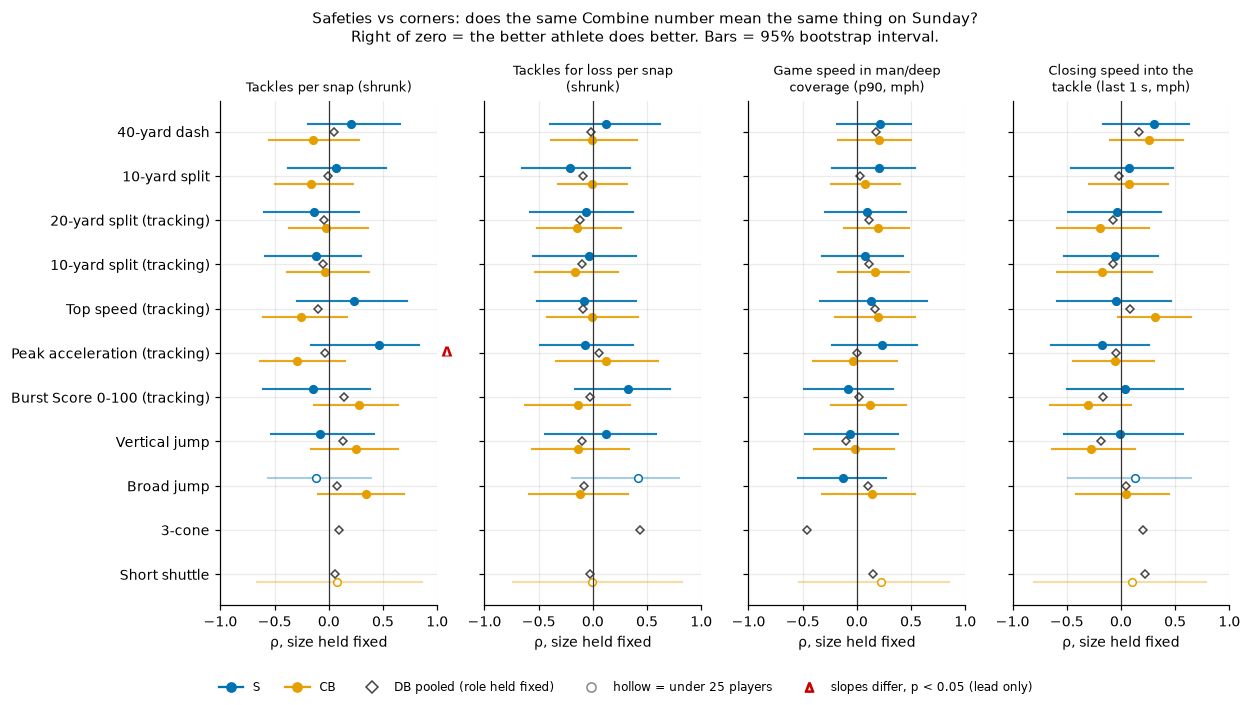

In [7]:
fig_forest(cells, ints, "DB", FIGDIR / "sub_fig2_forest_s_vs_cb.png")

## 4. Edge rushers vs interior linemen
Red = edge rushers, green = interior linemen, hollow diamond = all linemen pooled with role held fixed.

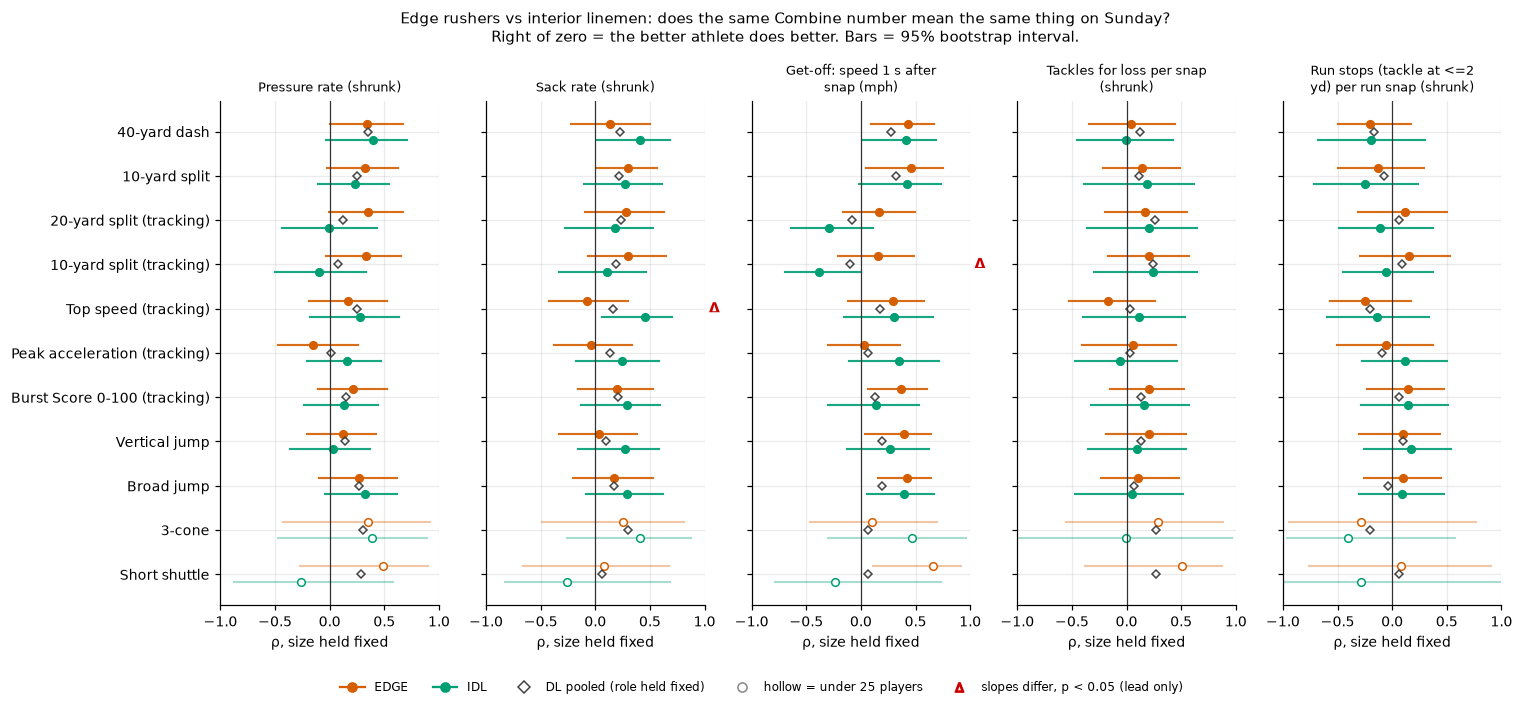

In [8]:
fig_forest(cells, ints, "DL", FIGDIR / "sub_fig3_forest_edge_vs_idl.png")

## 5. Do the subgroups really differ? (interaction tests)
For each Combine number and game result we ask: is the size-controlled link different for S than for CB (or EDGE than IDL)? Size and draft year are removed *inside* each subgroup first, so a corner being lighter than a safety cannot fake a difference. The test is a Freedman–Lane permutation of the interaction term (10,000 permutations), with a stratified player bootstrap for the interval and BH-FDR within each pair. The grey band is the smallest gap these sample sizes can reliably detect. The table after the figure flags links that are at least 0.30 in *both* subgroups but weaker when pooled.

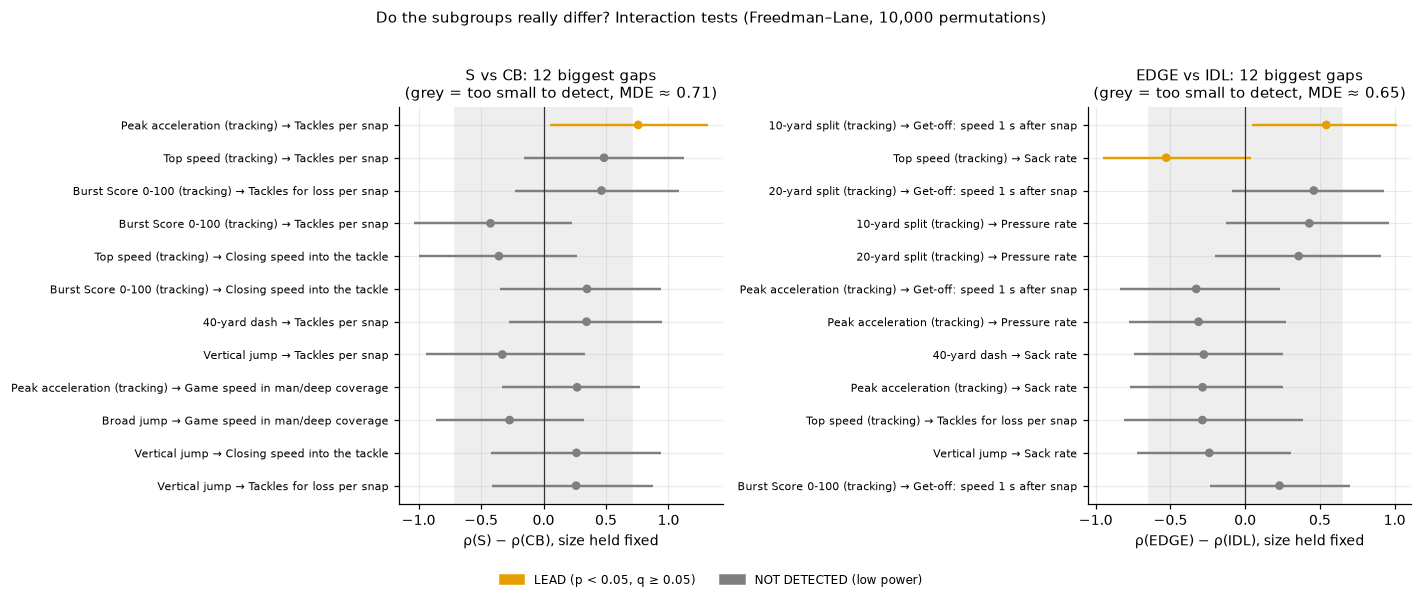

,sub_a,sub_b,test_label,outcome_label,n_a,n_b,rho_a,rho_b,diff,diff_lo,diff_hi,p_int,q_int,mde_diff,verdict
0,S,CB,Peak acceleration (tracking),Tackles per snap (shrunk),26,32,0.467,-0.290,0.757,0.051,1.316,0.003,0.101,0.705,LEAD (preliminary)
1,EDGE,IDL,10-yard split (tracking),Get-off: speed 1 s after snap (mph),38,33,0.157,-0.386,0.543,0.047,1.013,0.021,0.383,0.645,LEAD (preliminary)
2,EDGE,IDL,Top speed (tracking),Sack rate (shrunk),38,33,-0.078,0.450,-0.529,-0.954,0.037,0.028,0.383,0.645,LEAD (preliminary)
3,EDGE,IDL,20-yard split (tracking),Get-off: speed 1 s after snap (mph),38,33,0.167,-0.292,0.459,-0.088,0.931,0.056,0.603,0.645,NOT DETECTED (low power)
4,S,CB,Top speed (tracking),Tackles per snap (shrunk),26,32,0.231,-0.254,0.484,-0.158,1.123,0.070,0.646,0.705,NOT DETECTED (low power)
5,EDGE,IDL,10-yard split (tracking),Pressure rate (shrunk),38,33,0.332,-0.097,0.429,-0.129,0.963,0.075,0.675,0.645,NOT DETECTED (low power)
6,S,CB,Burst Score 0-100 (tracking),Tackles for loss per snap (shrunk),25,32,0.325,-0.139,0.464,-0.230,1.082,0.084,0.646,0.712,NOT DETECTED (low power)
7,S,CB,Burst Score 0-100 (tracking),Tackles per snap (shrunk),25,32,-0.142,0.283,-0.425,-1.037,0.225,0.108,0.646,0.712,NOT DETECTED (low power)
8,EDGE,IDL,20-yard split (tracking),Pressure rate (shrunk),38,33,0.350,-0.008,0.358,-0.200,0.907,0.135,1.000,0.645,NOT DETECTED (low power)
9,EDGE,IDL,Peak acceleration (tracking),Get-off: speed 1 s after snap (mph),38,33,0.025,0.353,-0.327,-0.836,0.234,0.166,1.000,0.645,NOT DETECTED (low power)


In [9]:
fig_diff(ints, FIGDIR / "sub_fig4_interactions.png")
d = ints[(ints[["n_a", "n_b"]].min(axis=1) >= 25)].sort_values("p_int").head(10)
display(d[["sub_a", "sub_b", "test_label", "outcome_label", "n_a", "n_b", "rho_a", "rho_b", "diff", "diff_lo", "diff_hi", "p_int", "q_int", "mde_diff", "verdict"]].round(3).reset_index(drop=True))

In [10]:
# pooling check: is the pooled (role held fixed) link weaker than BOTH subgroups?
pv = cells[cells.n >= 25].pivot_table(index=["group", "test_label", "outcome_label"], columns="sub", values="rho")
rows = []
for grp, (a, b, _) in PAIRS.items():
    g = pv.loc[grp][[a, b, f"{grp} pooled"]].dropna()
    g = g[(np.sign(g[a]) == np.sign(g[b])) & (g[[a, b]].abs().min(axis=1) >= 0.30) & (g[f"{grp} pooled"].abs() < g[[a, b]].abs().min(axis=1))]
    rows.append(g.assign(group=grp))
display(pd.concat(rows).round(2))

,sub,S,CB,DB pooled,group,EDGE,IDL,DL pooled
test_label,outcome_label,,,,,,,
10-yard split,Get-off: speed 1 s after snap (mph),NaN,NaN,NaN,DL,0.46,0.42,0.32
40-yard dash,Get-off: speed 1 s after snap (mph),NaN,NaN,NaN,DL,0.43,0.41,0.28
Broad jump,Get-off: speed 1 s after snap (mph),NaN,NaN,NaN,DL,0.42,0.39,0.19


## 6. Preliminary findings
*Numbers below are from the run dated 11/2026. Nothing reaches q < 0.05 with held-out support, so every item is a preliminary lead, not a finding.*

1. **Edge rushers: the explosive tests show up in get-off.** With size held fixed, a faster official 10-yard split goes with a faster first second off the snap (ρ +0.46, 95% CI +0.05 to +0.75, n 39, q 0.14; held-out classes agree, 3 of 3). The broad jump (+0.42, n 42, q 0.14, held-out 2 of 3), the 40 (+0.43) and the vertical (+0.40) say the same thing. **LEAD.**
2. **Interior linemen: straight-line speed shows up in sacks, but not for edges.** Tracked Combine top speed goes with a higher sack rate for interior linemen (ρ +0.45, CI +0.06 to +0.70, n 33, q 0.29; held-out 3 of 3), and so does the 40 (+0.41, q 0.29, held-out 3 of 3). For edge rushers, top speed shows nothing for sacks (−0.08). The gap (−0.53) is the biggest lineman difference we see (interaction p 0.03, q 0.38), but these samples can only reliably detect gaps of about 0.65. **LEAD, difference NOT DETECTED (low power) after correction.**
3. **Pooling the line hides some of the get-off signal.** Explosiveness relates to get-off about equally inside each subgroup (10-yard split: EDGE +0.46, IDL +0.42; broad jump: +0.42 and +0.39), but the pooled lineman reading is weaker (+0.32 and +0.19), even with role held fixed. The slopes do not differ between edge and interior, so the lesson is to rank a lineman's Combine against his own sub-position, not against every lineman.
4. **Safeties vs corners: one possible split, on tackling.** A safety's peak acceleration in the 40 leans toward more tackles per snap (ρ +0.47, n 26), while a corner's leans the other way (−0.29). The gap (+0.76, CI +0.05 to +1.32) is the strongest interaction in the whole notebook (p 0.003, q 0.10), but the safety link alone has an interval that crosses zero, q 0.90, and fails the held-out check. **LEAD for the difference only; treat as a question to chase, not an answer.**
5. **Coverage speed reads the same for both DB groups.** The 40 and top speed relate to game speed in man or deep coverage at about +0.1 to +0.2 for both safeties (n 30 to 31) and corners (n 37 to 38), and the gap between them is near zero (+0.01 and −0.07). NOT DETECTED (low power): safeties need about 0.53 and corners about 0.48 to detect, and a safety-vs-corner gap needs about 0.66. No sign that pooling defensive backs hides anything here.

**Real vs not detected.** Of 99 interaction tests, **none** clears q < 0.05, so no S-vs-CB or EDGE-vs-IDL difference is established. Three are leads at p < 0.05 (safety-vs-corner peak acceleration to tackles; edge-vs-interior top speed to sacks; edge-vs-interior *tracked* 10-yard split to get-off, which rests on an odd negative interior link from a tracked split that agrees only loosely with the official one). Everything else is NOT DETECTED (low power): with 26 to 38 players per side, only gaps of about **0.62 to 0.65 (EDGE vs IDL)** and **0.66 to 0.73 (S vs CB)** are reliably detectable. 21 tests (mostly 3-cone and shuttle) have too few players to tell.

## 7. Methods and limits
- **Combine side.** Official 40, 10-yard split, vertical, broad, 3-cone and shuttle. From the 10 Hz Combine sensor (best 40 attempt = highest top speed): top speed, tracked 10- and 20-yard splits, and peak acceleration. **Burst Score** = 0 to 100 within-subgroup blend of the tracked 20-yard time and the two jumps.
- **Game side (regular season, plays that stood).** DB: tackles and tackles for loss per defensive snap, game speed in man or deep coverage (90th percentile of per-play top speed), and speed over the last second into a tackle. DL: pressure and sack rate per pass-rush snap, get-off (speed 1.0 s after the snap, median), tackles for loss per snap, and run stops (a tackle at 2 yards or less) per run snap.
- **Statistics.** Rank partial correlation holding draft year, weight and height fixed; 2,000-draw player bootstrap; Freedman–Lane permutation p (10,000); BH-FDR within each subgroup; leave-one-draft-class-out ridge check (1,000 permutations); MDE by Fisher-z (rank variance factor 1.06). Verdicts: **TRANSLATES** = q < 0.05, interval excludes zero and held-out classes agree. **LEAD (preliminary)** = interval excludes zero or p < 0.05, but q does not clear. **SIZE, NOT SPEED** = a year-only link of 0.30+ that halves once size is held fixed. **TOO FEW TO TELL** = under 25 players. **NOT DETECTED (low power)** = none of the above; not proof of no link.
- **Limits.** Subgroups hold 26 to 50 players per test, so only links of about 0.45 to 0.60 are reliably detectable, and *differences* between subgroups need gaps of about 0.62 to 0.73. Same players generate and test the leads; held-out draft classes are the only out-of-sample check. Tracked 10-yard splits track the official 10-yard split only loosely (ρ about 0.3), so trust the official split first. No blocker, ball-carrier or quarterback tracks are linked, so these are associations, not causes.
